# 1. Read the file

In [4]:
from pathlib import Path
import pandas as pd

# need to change to the real path
folder = Path("/Users/densoul/Desktop/600")
input_file = folder / "cleaned_latest_data.csv"

data = pd.read_csv(
    input_file,
    dtype={"Participant ID": "string"},
    low_memory=False,
)

data.columns = data.columns.str.strip()

print(f"Records: {len(data):,}")
display(data.head())

Records: 13,053


,Participant ID,Survey year,Immediate recall,Delayed recall,Serial 7s,Backwards counting,Derived 0-27 cognition score,Hypertension,Diabetes,Cancer,...,Chronic Disease Burden,Age,Sex,Race/ethnicity,Education,Marital status,Smoking,BMI,Interview mode,Proxy respondent
0,010001010,2022,4.0,0.0,5.0,2.0,11.0,0.0,0.0,0.0,...,0.0,83.0,1,Non-Hispanic White,12.0,8.0,0.0,19.5,1.0,0.0
1,010003030,2022,5.0,2.0,4.0,2.0,13.0,1.0,0.0,0.0,...,5.0,66.0,2,Non-Hispanic White,16.0,7.0,0.0,36.0,1.0,0.0
2,010004040,2022,7.0,5.0,5.0,2.0,19.0,1.0,0.0,0.0,...,2.0,77.0,2,Non-Hispanic White,12.0,1.0,0.0,30.1,1.0,0.0
3,010013040,2022,5.0,6.0,5.0,2.0,18.0,1.0,0.0,0.0,...,1.0,74.0,2,Non-Hispanic White,13.0,5.0,0.0,25.2,1.0,0.0
4,010038010,2022,4.0,4.0,5.0,2.0,15.0,1.0,0.0,0.0,...,2.0,85.0,1,Non-Hispanic White,16.0,1.0,0.0,22.8,1.0,0.0


# 2.Redefine the numerical codes for each race category

In [5]:
race_mapping = {
    "Non-Hispanic White": 0,
    "Non-Hispanic Other": 1,
    "Non-Hispanic Black": 2,
    "Hispanic": 3,
}

race = data["Race/ethnicity"].astype("string").str.strip()

invalid = race.isna() | ~race.isin(race_mapping)
if invalid.any():
    raise ValueError(
        f"Missing or unexpected race values: "
        f"{race.loc[invalid].unique().tolist()}"
    )

data["Race/ethnicity"] = race.map(race_mapping).astype("int64")

print("Race/ethnicity counts after recoding:")
print(data["Race/ethnicity"].value_counts().sort_index())

Race/ethnicity counts after recoding:
Race/ethnicity
0    8186
1     375
2    2616
3    1876
Name: count, dtype: int64


In [6]:
print("Data types:")
print(data.dtypes)

non_numeric = data.select_dtypes(exclude="number").columns.tolist()
print("\nNon-numeric columns:", non_numeric)

model_columns = data.drop(columns=["Participant ID"])

print(
    "\nAll remaining columns are numeric:",
    model_columns.select_dtypes(exclude="number").empty,
)

Data types:
Participant ID                   string
Survey year                       int64
Immediate recall                float64
Delayed recall                  float64
Serial 7s                       float64
Backwards counting              float64
Derived 0-27 cognition score    float64
Hypertension                    float64
Diabetes                        float64
Cancer                          float64
Chronic lung disease            float64
Heart disease                   float64
Stroke                          float64
Arthritis                       float64
Chronic Disease Burden          float64
Age                             float64
Sex                               int64
Race/ethnicity                    int64
Education                       float64
Marital status                  float64
Smoking                         float64
BMI                             float64
Interview mode                  float64
Proxy respondent                float64
dtype: object

Non-numeric c

# 3.Pre-processing
## Define X1 and X2

In [7]:
demographic_features = [ "Age", "Sex", "Race/ethnicity", "Education", "Marital status"]

health_features = ["Smoking","BMI"]

# Model 1: Demographics + health condition
x1_features = demographic_features + health_features

# Model 2: Demographics + health condition + Chronic Disease Burden
x2_features = x1_features + ["Chronic Disease Burden"]

X1 = data[x1_features].copy()
X2 = data[x2_features].copy()

print("Model 1 features:", X1.columns.tolist())
print("Model 1 shape:", X1.shape)

print("\nModel 2 features:", X2.columns.tolist())
print("Model 2 shape:", X2.shape)


Model 1 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI']
Model 1 shape: (13053, 7)

Model 2 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI', 'Chronic Disease Burden']
Model 2 shape: (13053, 8)


## Define Y

In [8]:
# Outcome: Cognitive Score (0–27)
Y = data["Derived 0-27 cognition score"].copy()

print("Outcome:",Y.name)
print("Shape:", Y.shape)
print("Missing values:", Y.isna().sum())
print("Score range:", Y.min(), "to", Y.max())

assert X1.index.equals(Y.index)
assert X2.index.equals(Y.index)

Outcome: Derived 0-27 cognition score
Shape: (13053,)
Missing values: 0
Score range: 0.0 to 27.0


## Split the Data into Training and Test Sets

Use `train_test_split()` to divide the data into 70% training and 30% test sets.

- **X1:** Demographics + health condition (Model 1).
- **X2:** Demographics + health condition + Chronic Disease Burden (Model 2).
- **y:** Cognitive Score (0–27).

Split X1, X2, and y together so both models use the same participants in their training and test sets. Set `shuffle=True` to shuffle the records before splitting and `random_state=3` to make the split reproducible.

Use the training set to fit the models and the test set to evaluate and compare their predictive performance. Fit any preprocessing steps on the training set only, then apply them to the test set.

In [9]:
from sklearn.model_selection import train_test_split

(X1_trainset,X1_testset,X2_trainset,X2_testset,Y_trainset,Y_testset,) = train_test_split(
    X1,X2,Y, test_size=0.3,random_state=3,shuffle=True,)

# Check that both models use the same records
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)
assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

print("X1 training set:", X1_trainset.shape)
print("X1 test set:", X1_testset.shape)
print("X2 training set:", X2_trainset.shape)
print("X2 test set:", X2_testset.shape)
print("y training set:", Y_trainset.shape)
print("y test set:", Y_testset.shape)

X1 training set: (9137, 7)
X1 test set: (3916, 7)
X2 training set: (9137, 8)
X2 test set: (3916, 8)
y training set: (9137,)
y test set: (3916,)


## Step 1 — Import CatBoost

Import CatBoostRegressor to predict Cognitive Score (Y).

Compare two models:
- Model 1: Demographics + Smoking + BMI.
- Model 2: The same predictors + Chronic Disease Burden.

Use the same training and test participants as the linear regression
and XGBoost analyses.

In [11]:
from catboost import CatBoostRegressor

## Step 2 — Check the Training and Test Data

Use the existing training and test split.

Confirm that X1, X2, and Y contain the same participants in the same
order within each set.

Check for missing or infinite values, duplicate record indices,
and overlap between training and test records.

In [12]:
import numpy as np

# Check alignment between predictors and outcomes
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)

assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

# Check for missing or infinite values
datasets = {
    "X1_trainset": X1_trainset,
    "X2_trainset": X2_trainset,
    "Y_trainset": Y_trainset,
    "X1_testset": X1_testset,
    "X2_testset": X2_testset,
    "Y_testset": Y_testset,
}

for name, dataset in datasets.items():
    if not np.isfinite(dataset.to_numpy(dtype=float)).all():
        raise ValueError(
            f"{name} contains missing or infinite values."
        )

# Check record indices
assert X1_trainset.index.is_unique
assert X1_testset.index.is_unique
assert X1_trainset.index.intersection(X1_testset.index).empty

print("All checks passed.")
print(f"Training records: {len(Y_trainset):,}")
print(f"Test records: {len(Y_testset):,}")

All checks passed.
Training records: 9,137
Test records: 3,916


## Step 3 — Prepare Categorical Features for CatBoost

Treat Sex, Race/ethnicity, Marital status, and Smoking as categorical
features and convert their category labels to strings.

Keep Age, Education, BMI, and Chronic Disease Burden as numerical
features in their original units.

Create separate copies for CatBoost while preserving the existing
data, row order, and training/test split.

In [13]:
import pandas as pd

catboost_categorical_features = [
    "Sex",
    "Race/ethnicity",
    "Marital status",
    "Smoking",
]

def prepare_catboost_data(X):
    X_cat = X.copy()

    for column in catboost_categorical_features:
        # Standardize numeric labels: both 1 and 1.0 become "1"
        labels = pd.to_numeric(X_cat[column], errors="raise")

        if not (labels == labels.round()).all():
            raise ValueError(
                f"{column} contains non-integer category labels."
            )

        X_cat[column] = labels.astype("int64").astype(str)

    return X_cat

# Prepare separate inputs for CatBoost
X1_cat_trainset = prepare_catboost_data(X1_trainset)
X1_cat_testset = prepare_catboost_data(X1_testset)

X2_cat_trainset = prepare_catboost_data(X2_trainset)
X2_cat_testset = prepare_catboost_data(X2_testset)

print("CatBoost input data are ready.")
display(X2_cat_trainset.head())

CatBoost input data are ready.


,Age,Sex,Race/ethnicity,Education,Marital status,Smoking,BMI,Chronic Disease Burden
2431,92.0,1,0,17.0,1,0,28.6,2.0
3769,80.0,1,2,12.0,1,0,24.3,4.0
1784,85.0,1,0,17.0,7,0,27.4,5.0
6662,73.0,2,0,16.0,3,0,37.5,2.0
3592,76.0,2,2,17.0,1,0,26.6,2.0


## Step 4 — Build the CatBoost Models

Create two CatBoost regression models with the same initial
hyperparameters and categorical feature definitions.

- Model 1: Demographics + Smoking + BMI.
- Model 2: The same predictors + Chronic Disease Burden.

Use RMSE as the training loss.
These initial settings have not been tuned.
Training will follow in the next step.

In [14]:
catboost_params = {
    "loss_function": "RMSE",
    "iterations": 300,
    "learning_rate": 0.05,
    "depth": 3,
    "l2_leaf_reg": 3,
    "cat_features": catboost_categorical_features,
    "random_seed": 3,
    "thread_count": 4,
    "verbose": False,
    "allow_writing_files": False,
}

cat_model1 = CatBoostRegressor(**catboost_params)
cat_model2 = CatBoostRegressor(**catboost_params)

print("Model 1 and Model 2 are ready for training.")

Model 1 and Model 2 are ready for training.


## Step 5 — Train Model 1

Fit CatBoost Model 1 using X1_cat_trainset and Y_trainset.

The model uses demographics, Smoking, and BMI to predict Cognitive
Score, with the specified categorical features handled by CatBoost.

Keep the test set reserved for later evaluation.

In [15]:
cat_model1.fit(X1_cat_trainset, Y_trainset)

print("Model 1 training completed.")

Model 1 training completed.


## Step 6 — Train Model 2

Fit CatBoost Model 2 using X2_cat_trainset and Y_trainset.

Use the same training participants, outcome, and initial
hyperparameters as Model 1, with Chronic Disease Burden added
to the predictors.

Keep the test set reserved for later evaluation.

In [16]:
cat_model2.fit(X2_cat_trainset, Y_trainset)

print("Model 2 training completed.")

Model 2 training completed.


## Step 7 — Predict Cognitive Scores on the Test Set

Use the trained CatBoost models to predict Cognitive Scores
for the same test participants.

Model 1 uses X1_cat_testset, and Model 2 uses X2_cat_testset.

Display both predictions alongside the actual scores in Y_testset.

In [17]:
Y_pred_cat_m1 = cat_model1.predict(X1_cat_testset)
Y_pred_cat_m2 = cat_model2.predict(X2_cat_testset)

cat_prediction_results = pd.DataFrame(
    {
        "Actual Cognitive Score": Y_testset,
        "Model 1 Prediction": Y_pred_cat_m1,
        "Model 2 Prediction": Y_pred_cat_m2,
    },
    index=Y_testset.index,
)

display(cat_prediction_results.head(10))

,Actual Cognitive Score,Model 1 Prediction,Model 2 Prediction
3277,15.0,13.507821,13.376311
1411,8.0,12.839673,12.874810
2877,14.0,10.914488,11.673102
4242,16.0,14.274080,14.594278
8473,18.0,17.486489,17.741521
9176,12.0,16.118387,15.920231
11635,10.0,15.548157,15.929875
7962,18.0,16.370652,16.288527
8378,16.0,14.603297,14.837108
4227,12.0,16.099711,16.235104


## Step 8 — Evaluate Model Performance

Compare predicted Cognitive Scores with the actual values
in Y_testset.

Calculate test-set MAE, RMSE, and R² for both CatBoost models.
Lower MAE and RMSE indicate better predictions, while higher
R² indicates better performance.

Compare Model 1 and Model 2 to assess whether adding
Chronic Disease Burden improves test-set prediction.

In [18]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

def evaluate_cat_regression(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

cat_results = pd.DataFrame(
    [
        evaluate_cat_regression(Y_testset, Y_pred_cat_m1),
        evaluate_cat_regression(Y_testset, Y_pred_cat_m2),
    ],
    index=["Model 1", "Model 2"],
)

display(cat_results.round(4))

,MAE,RMSE,R²
Model 1,3.3348,4.2066,0.2882
Model 2,3.3246,4.1965,0.2916


## Step 9 — Define Hyperparameter Search and Cross-Validation

Search 27 combinations of iterations, depth, and learning rate.
Keep l2_leaf_reg fixed at 3.

Use the same five-fold splits for both CatBoost models.
Select parameters using mean validation RMSE within the training set.

Preserve the baseline models and keep the original test set
out of parameter selection.

In [19]:
from sklearn.model_selection import KFold, ParameterGrid

# Confirm the same training participants and row order
assert X1_cat_trainset.index.equals(X2_cat_trainset.index)
assert X1_cat_trainset.index.equals(Y_trainset.index)

# Define candidate parameters
cat_param_grid = {
    "iterations": [100, 300, 500],
    "depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.1],
}

# Use the same fold settings as the XGBoost analysis
cat_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=3,
)

# Save the folds for both models
cat_cv_splits = list(cat_cv.split(X1_cat_trainset))

print(f"Parameter combinations: {len(ParameterGrid(cat_param_grid))}")
print(f"Cross-validation folds: {len(cat_cv_splits)}")

Parameter combinations: 27
Cross-validation folds: 5


## Step 10 — Tune Model 1

Use GridSearchCV to evaluate all 27 parameter combinations
with the predefined five-fold splits.

Select the combination with the lowest mean validation RMSE,
then refit the selected model on the full training set.

Preserve the original Model 1 as a baseline.
Keep the test set out of parameter selection.

In [22]:
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV

# Pass categorical features during fitting instead of construction
cat_tuning_params = {
    key: value
    for key, value in catboost_params.items()
    if key != "cat_features"
}

# Create a new, untrained model
cat_tuning_model1 = CatBoostRegressor(**cat_tuning_params)

# Define the parameter search
cat_search_m1 = GridSearchCV(
    estimator=cat_tuning_model1,
    param_grid=cat_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cat_cv_splits,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

# Tune using the training set only
cat_search_m1.fit(
    X1_cat_trainset,
    Y_trainset,
    cat_features=catboost_categorical_features,
)

# Save the selected and refitted model
cat_tuned_model1 = cat_search_m1.best_estimator_

print("Selected parameters for Model 1:")
print(cat_search_m1.best_params_)

print(
    "Mean validation RMSE:",
    round(-cat_search_m1.best_score_, 4),
)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected parameters for Model 1:
{'depth': 4, 'iterations': 300, 'learning_rate': 0.03}
Mean validation RMSE: 4.1843


## Step 11 — Tune Model 2

Tune Model 2 using the same parameter grid, cross-validation
folds, and RMSE scoring as Model 1.

Select the combination with the lowest mean validation RMSE,
then refit the selected model on the full training set.

Model 2 adds Chronic Disease Burden.
Keep the test set out of parameter selection.

In [23]:
# Create a new, untrained model using the same initial settings
cat_tuning_model2 = CatBoostRegressor(**cat_tuning_params)

# Define the parameter search
cat_search_m2 = GridSearchCV(
    estimator=cat_tuning_model2,
    param_grid=cat_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cat_cv_splits,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

# Tune using Model 2's training features
cat_search_m2.fit(
    X2_cat_trainset,
    Y_trainset,
    cat_features=catboost_categorical_features,
)

# Save the selected and refitted model
cat_tuned_model2 = cat_search_m2.best_estimator_

print("Selected parameters for Model 2:")
print(cat_search_m2.best_params_)

print(
    "Mean validation RMSE:",
    round(-cat_search_m2.best_score_, 4),
)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected parameters for Model 2:
{'depth': 4, 'iterations': 300, 'learning_rate': 0.03}
Mean validation RMSE: 4.1733


## Step 12 — Predict Test-Set Scores with the Tuned Models

Use the tuned CatBoost models to predict Cognitive Scores
for the original test participants.

Both models have already been refitted on the full training set.

Save the tuned predictions separately from the baseline predictions
for later comparison.

In [24]:
# Predict using the tuned models
Y_pred_cat_tuned_m1 = cat_tuned_model1.predict(X1_cat_testset)
Y_pred_cat_tuned_m2 = cat_tuned_model2.predict(X2_cat_testset)

# Display predictions alongside the actual scores
cat_tuned_prediction_results = pd.DataFrame(
    {
        "Actual Cognitive Score": Y_testset,
        "Tuned Model 1 Prediction": Y_pred_cat_tuned_m1,
        "Tuned Model 2 Prediction": Y_pred_cat_tuned_m2,
    },
    index=Y_testset.index,
)

display(cat_tuned_prediction_results.head(10))

,Actual Cognitive Score,Tuned Model 1 Prediction,Tuned Model 2 Prediction
3277,15.0,13.512801,13.320431
1411,8.0,12.900465,12.844194
2877,14.0,11.303365,11.572984
4242,16.0,14.096750,14.237655
8473,18.0,17.516956,17.785581
9176,12.0,16.217379,15.830853
11635,10.0,15.361005,15.772457
7962,18.0,16.368987,16.114805
8378,16.0,14.526512,14.666396
4227,12.0,15.966353,16.384218


## Step 13 — Compare Baseline and Tuned Model Performance

Calculate test-set MAE, RMSE, and R² for the tuned CatBoost models.

Compare baseline and tuned results for both models on the same
test participants.

Lower MAE and RMSE indicate better predictions, while higher R²
indicates better performance.

In [25]:
# Evaluate the tuned models
cat_tuned_results = pd.DataFrame(
    [
        evaluate_cat_regression(Y_testset, Y_pred_cat_tuned_m1),
        evaluate_cat_regression(Y_testset, Y_pred_cat_tuned_m2),
    ],
    index=["Model 1", "Model 2"],
)

# Combine baseline and tuned results
cat_comparison_results = pd.concat(
    [cat_results, cat_tuned_results],
    keys=["Baseline", "Tuned"],
    names=["Settings", "Model"],
)

display(cat_comparison_results.round(4))

MAE    RMSE      R²
Settings Model                          
Baseline Model 1  3.3348  4.2066  0.2882
         Model 2  3.3246  4.1965  0.2916
Tuned    Model 1  3.3354  4.2072  0.2880
         Model 2  3.3244  4.1941  0.2924

## Step 14 — Visualize Actual and Predicted Cognitive Scores

Plot actual Cognitive Scores against predictions from the two
tuned CatBoost models using the same test participants and axis scales.

Each point represents one participant.
The dashed diagonal line represents perfect prediction.

Display test-set RMSE and R² for each model.

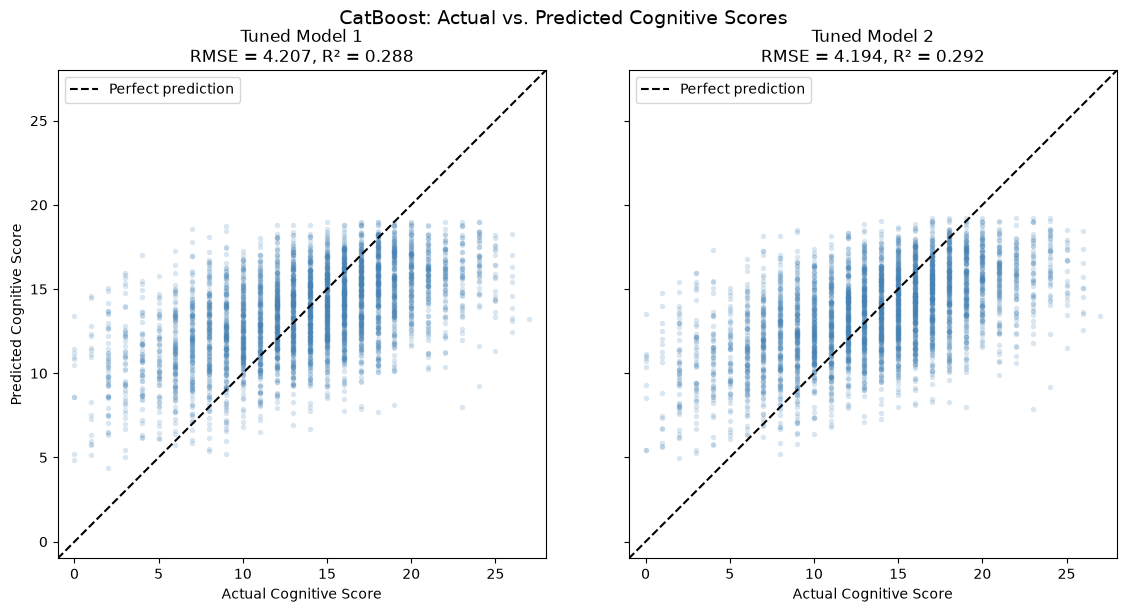

Figure saved to: /Users/densoul/Desktop/600/catboost_tuned_actual_vs_predicted.png


In [26]:
import matplotlib.pyplot as plt
from pathlib import Path

# Define a shared axis range
lower = min(
    0,
    Y_testset.min(),
    Y_pred_cat_tuned_m1.min(),
    Y_pred_cat_tuned_m2.min(),
) - 1

upper = max(
    27,
    Y_testset.max(),
    Y_pred_cat_tuned_m1.max(),
    Y_pred_cat_tuned_m2.max(),
) + 1

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharex=True,
    sharey=True,
)

for ax, name, predictions in [
    (axes[0], "Model 1", Y_pred_cat_tuned_m1),
    (axes[1], "Model 2", Y_pred_cat_tuned_m2),
]:
    ax.scatter(
        Y_testset,
        predictions,
        alpha=0.2,
        s=15,
        color="steelblue",
        linewidths=0,
    )

    # Perfect prediction line
    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="black",
        label="Perfect prediction",
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual Cognitive Score")

    ax.set_title(
        f"Tuned {name}\n"
        f"RMSE = {cat_tuned_results.loc[name, 'RMSE']:.3f}, "
        f"R² = {cat_tuned_results.loc[name, 'R²']:.3f}"
    )

    ax.legend(loc="upper left")

axes[0].set_ylabel("Predicted Cognitive Score")

fig.suptitle(
    "CatBoost: Actual vs. Predicted Cognitive Scores",
    fontsize=14,
)

fig.tight_layout()

# Save a high-resolution figure for the project
figure_file = Path.cwd() / "catboost_tuned_actual_vs_predicted.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved to: {figure_file}")

## Step 15 — Visualize Baseline Model Predictions

Plot actual Cognitive Scores against predictions from the baseline
CatBoost models using the same test participants and axis scales.

The dashed diagonal line represents perfect prediction.
Display test-set RMSE and R² for each baseline model.

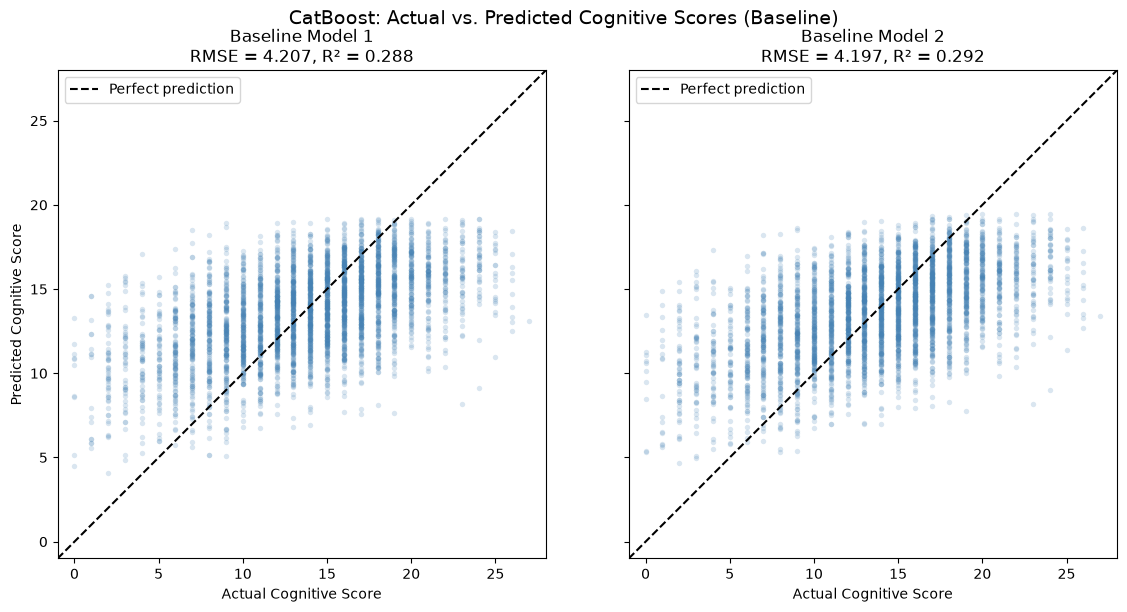

Figure saved to: /Users/densoul/Desktop/600/catboost_baseline_actual_vs_predicted.png


In [27]:
import matplotlib.pyplot as plt
from pathlib import Path

# Define a shared axis range
lower = min(
    0,
    Y_testset.min(),
    Y_pred_cat_m1.min(),
    Y_pred_cat_m2.min(),
) - 1

upper = max(
    27,
    Y_testset.max(),
    Y_pred_cat_m1.max(),
    Y_pred_cat_m2.max(),
) + 1

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharex=True,
    sharey=True,
)

for ax, name, predictions in [
    (axes[0], "Model 1", Y_pred_cat_m1),
    (axes[1], "Model 2", Y_pred_cat_m2),
]:
    ax.scatter(
        Y_testset,
        predictions,
        alpha=0.2,
        s=15,
        color="steelblue",
        linewidths=0,
    )

    # Perfect prediction line
    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="black",
        label="Perfect prediction",
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual Cognitive Score")

    ax.set_title(
        f"Baseline {name}\n"
        f"RMSE = {cat_results.loc[name, 'RMSE']:.3f}, "
        f"R² = {cat_results.loc[name, 'R²']:.3f}"
    )

    ax.legend(loc="upper left")

axes[0].set_ylabel("Predicted Cognitive Score")

fig.suptitle(
    "CatBoost: Actual vs. Predicted Cognitive Scores (Baseline)",
    fontsize=14,
)

fig.tight_layout()

# Save a high-resolution figure for the project
figure_file = Path.cwd() / "catboost_baseline_actual_vs_predicted.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved to: {figure_file}")

## Step 16 — Compare Residuals Across Baseline and Tuned Models

Calculate residuals as actual minus predicted Cognitive Scores.

Plot residuals against predicted scores in four panels:
- Top row: Baseline Model 1 and Model 2.
- Bottom row: Tuned Model 1 and Model 2.

Use the same axis scales across all panels.
The horizontal line at zero represents no prediction error.

Examine systematic patterns and differences in residual spread.

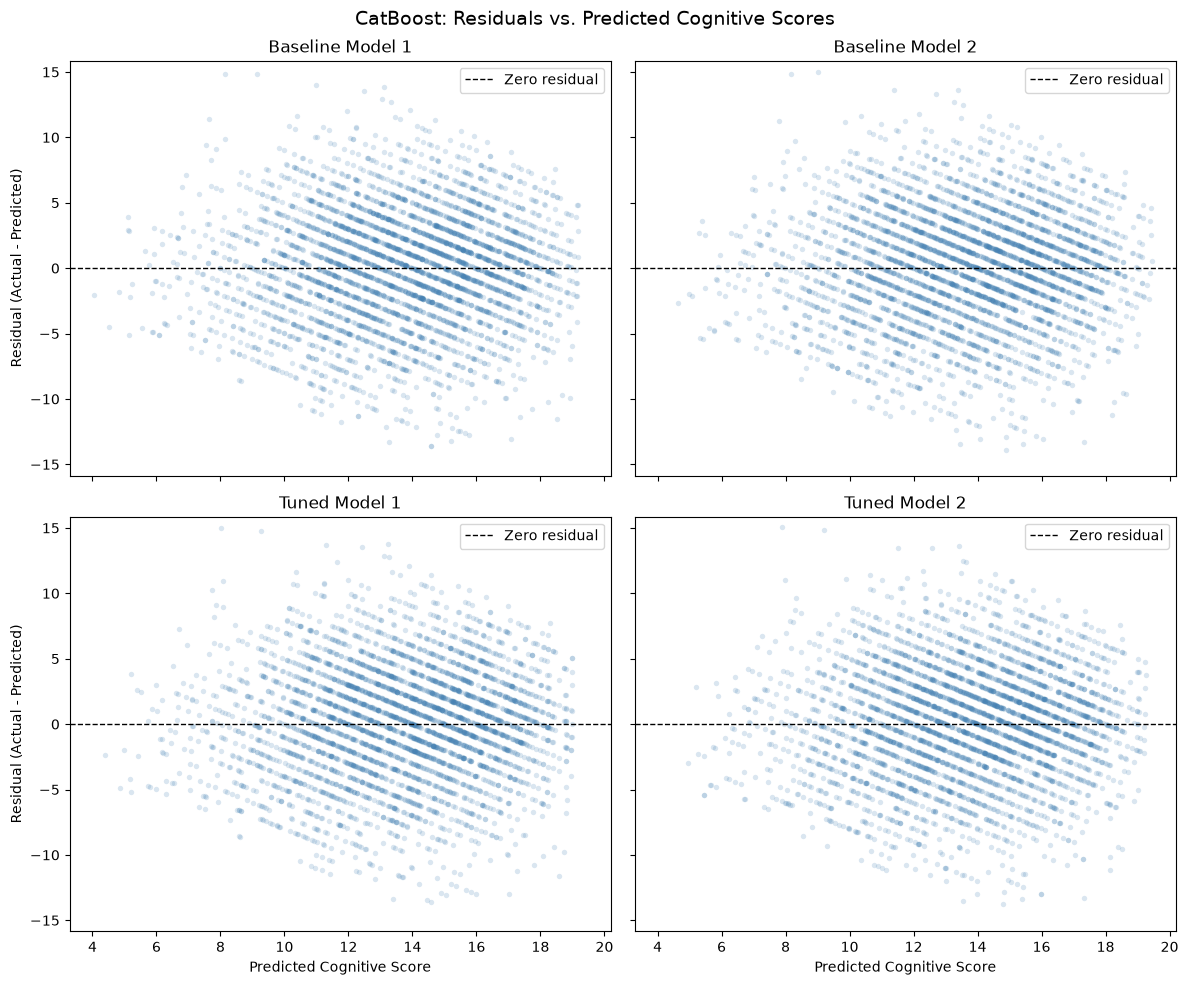

Figure saved to: /Users/densoul/Desktop/600/catboost_baseline_tuned_residuals.png


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

actual_scores = np.asarray(Y_testset, dtype=float)

# Arrange the four panels
panels = [
    ("Baseline Model 1", Y_pred_cat_m1),
    ("Baseline Model 2", Y_pred_cat_m2),
    ("Tuned Model 1", Y_pred_cat_tuned_m1),
    ("Tuned Model 2", Y_pred_cat_tuned_m2),
]

# Calculate residuals for all four models
residual_sets = [
    actual_scores - np.asarray(predictions, dtype=float)
    for _, predictions in panels
]

# Use a common, symmetric residual range around zero
all_residuals = np.concatenate(residual_sets)
y_limit = max(1.0, np.max(np.abs(all_residuals)) * 1.05)

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
)

for ax, (title, predictions), residuals in zip(
    axes.flat, panels, residual_sets
):
    ax.scatter(
        predictions,
        residuals,
        alpha=0.2,
        s=15,
        color="steelblue",
        linewidths=0,
    )

    ax.axhline(
        y=0,
        linestyle="--",
        color="black",
        linewidth=1,
        label="Zero residual",
    )

    ax.set_ylim(-y_limit, y_limit)
    ax.set_title(title)
    ax.legend(loc="upper right")

# Label the outer axes
for ax in axes[1, :]:
    ax.set_xlabel("Predicted Cognitive Score")

for ax in axes[:, 0]:
    ax.set_ylabel("Residual (Actual - Predicted)")

fig.suptitle(
    "CatBoost: Residuals vs. Predicted Cognitive Scores",
    fontsize=14,
)

fig.tight_layout()

# Save a high-resolution figure for the project
figure_file = Path.cwd() / "catboost_baseline_tuned_residuals.png"
fig.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()
print(f"Figure saved to: {figure_file}")